# Exercise 1

We first load a dataset and examine its dimensions.

In [1]:
# If you are running this on Google Colab, uncomment and run the following lines; otherwise ignore this cell
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

xy_data = np.load('Ex1_polyreg_data.npy')
# If running on Google Colab change path to '/content/drive/MyDrive/IB-Data-Science/Exercises/Ex1_polyreg_data.npy'

np.shape(xy_data)

(70, 2)

The matrix `xy_data` contains $70$ rows, each a data point of the form $(x_i,y_i)$ for $i=1, \ldots, 70$.

### 1a) Plot the data in a scatterplot.

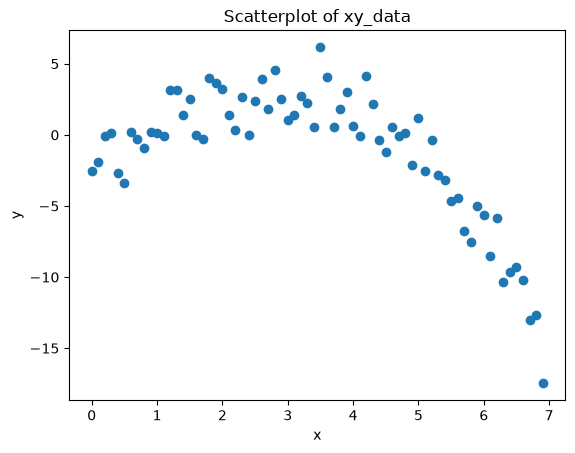

In [3]:
import matplotlib.pyplot as plt
# Your code for scatterplot here

x = xy_data[:, 0]
y = xy_data[:, 1]

plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatterplot of xy_data')
plt.show()

### 1b) Write a function `polyreg` to fit a polynomial of a given order to a dataset. 
The inputs to the function are a data matrix of dimension $N \times 2$,  and $k \geq 0$, the order of the polynomial.   The function should compute the coefficients of the polynomial $\beta_0 + \beta_1 x +  \ldots  +\beta_k x^{k}$ via least squares regression, and should return the coefficient vector, the fit, and the vector of residuals. 

If specified the degree $k$ is greater than or equal to $N$, then the function must fit an order $(N-1)$ polynomial and set the remaining coefficients to zero.

**NOTE**: You are *not* allowed to use the built-in function `np.polyfit`.

In [4]:
def polyreg(data_matrix, k):
    x_values = data_matrix[:, 0]
    y_values = data_matrix[:, 1]

    # Your code here
    # The function should return the the coefficient vector beta, the fit, and the vector of residuals
    all_ones = np.ones(np.shape(x_values))
    X = all_ones[:, np.newaxis]  # Start with the intercept term (column of ones)
    for i in range(1, k + 1):
        X = np.column_stack((X, x_values ** i))
    
    beta = np.linalg.lstsq(X, y_values, rcond=None)[0]
    fit = X @ beta
    residuals = y_values - fit

    return beta, fit, residuals

Use the tests below to check the outputs of the function you have written:

In [5]:
# Some tests to make sure your function is working correctly

xcol = np.arange(-1, 1.05, 0.1)
ycol = 2 - 7*xcol + 3*(xcol**2)  # We are generating data accoridng to y = 2 - 7x + 3x^2
test_matrix = np.transpose(np.vstack((xcol,ycol)))
test_matrix.shape

beta_test = polyreg(test_matrix, k=2)[0]
print(beta_test)
assert((np.round(beta_test[0], 3) == 2) and (np.round(beta_test[1], 3) == -7) and (np.round(beta_test[2], 3) == 3))  
# We want to check that using the function with k=2 recovers the coefficients exactly

# Now check the zeroth order fit, i.e., the function gives the correct output with k=0
beta_test = polyreg(test_matrix, k=0)[0]
res_test = polyreg(test_matrix, k=0)[2] #the last output of the function gives the vector of residuals

assert(np.round(beta_test, 3) == 3.1)
assert(np.round(np.linalg.norm(res_test), 3) == 19.937)

[ 2. -7.  3.]


### 1c) Use `polyreg` to fit polynomial models for the data in `xy_data` for $k=2,3,4$:

- Plot the fits for the three cases on the same plot together with the scatterplot of the data. The plots should be labelled and a legend included. 
- Compute and print the SSE and $R^2$ coefficient for each of the three cases.
- Which of the three models you would choose? Briefly justify your choice.

SSE_2 = 34.36
R^2 for k =  2  model =  0.9107
SSE_3 = 27.64
R^2 for k =  3  model =  0.9282
SSE_4 = 27.54
R^2 for k =  4  model =  0.9284


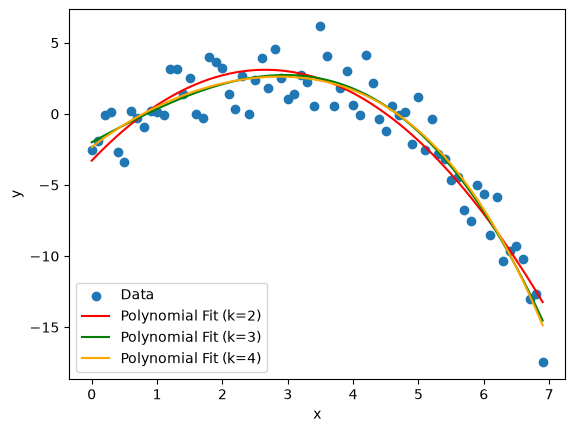

In [6]:
#Your code here
beta_0, fit_0, res_test = polyreg(xy_data, k=0)
SSE_0 = np.linalg.norm(res_test**2)

plt.scatter(xy_data[:, 0], xy_data[:, 1], label='Data')
color = ['red', 'green', 'orange']
for k in range(2,5):
    beta_k, fit_k, res_k = polyreg(xy_data, k)
    SSE = np.linalg.norm(res_k**2)
    print(f'SSE_{k} = {np.round(SSE, 2)}')
    print('R^2 for k = ', k, ' model = ', np.round(1- SSE/SSE_0, decimals = 4))
    plt.plot(xy_data[:, 0], fit_k, color=color[k-2], label=f'Polynomial Fit (k={k})')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()

plt.show()

 #### State which model you choose and briefly justify your choice.
 
 
Probably choose k = 4, as highest R^2 and lowest SSE, however k = 3 is almost identical
 
 

### 1d)  For the model you have chosen in the previous part (either $k=2/3/4)$:

- Plot the residuals in a scatter plot. 
- Plot a histogram of the residuals along with a Gaussian pdf with zero mean and the same standard deviation as the residuals.

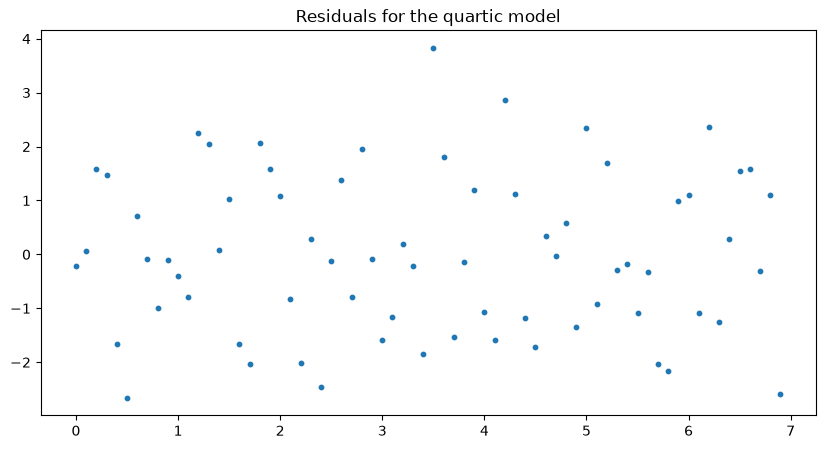

Mean of residuals for quartic model =  -0.0 Variance of residuals =  2.16


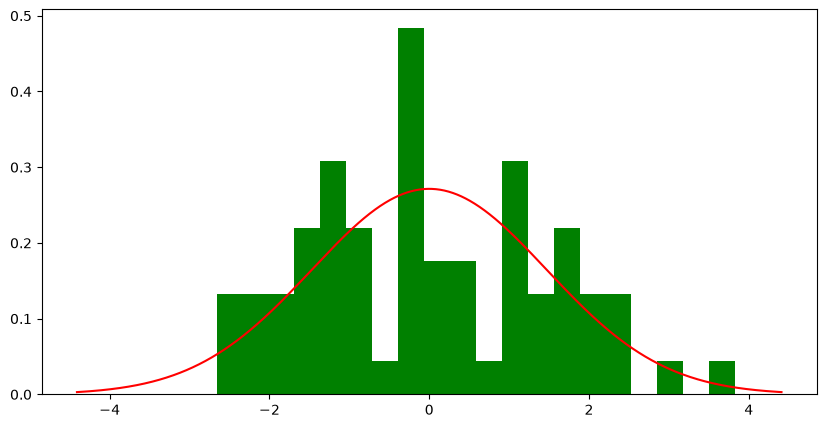

In [7]:
#Your code here
from scipy.stats import norm

beta_4, fit_4, res_4 = polyreg(xy_data, k=4)
SSE = np.linalg.norm((y - fit_4)**2)

plt.rcParams['figure.figsize'] = [10, 5]
plt.scatter(x, res_4, s=10)
plt.title('Residuals for the quartic model')
plt.savefig('quad_resid.png', bbox_inches = 'tight')
plt.show()

print('Mean of residuals for quartic model = ', np.round(np.mean(res_4), 3), 
      'Variance of residuals = ', np.round(np.var(res_4),3)) 

# Plot normed histogram of the residuals
n, bins, patches = plt.hist(res_4, bins=20, density=True, facecolor='green');

# Plot Gaussian pdf with same mean and variance as the residuals
res_4_stdev = np.std(res_4)  #standard deviation of residuals
xvals = np.linspace(-3*res_4_stdev,3*res_4_stdev,1000)
plt.plot(xvals, norm.pdf(xvals, loc=0, scale=res_4_stdev), 'r')
plt.show()